# Monte Carlo Option Pricing and Computing Exercise Boundaries using Isotonic Regression
Colin McGarry

In [ ]:
#Function to simulate price paths

import numpy as np

# Parameters from Gustafsson's tests
sigma = 0.15 # volatility
r = 0.03 # risk-free rate 
T = 1.0  # time to expiry
S0_values= (90.0, 100.0, 110.0) # same S_0 that Gustafsson used

# Using N=100 time steps for each path, M= 10^6 total paths

def gbm_paths(S0, N=100, M=1000000): 
    rng = np.random.default_rng() # random number generator
    dt = T / N
    z = rng.standard_normal((M, N)) # iid N(0,1) random variables. Note: different from Gustafsson's M/2 method
    increments = (r - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * z
    log_paths = np.hstack([np.zeros((M, 1)), np.cumsum(increments, axis=1)]) # sums up log-returns, starting with an initial value of 0
    return S0 * np.exp(log_paths)       


In [ ]:
# Simulate Paths for S_0 = 90, 100, 110

paths_90 = gbm_paths(90)
paths_100 = gbm_paths(100)
paths_110 = gbm_paths(110)

# Check mean of terminal values of paths against exact value S_0 *e^(rT)

ST_90 = paths_90[:,-1]
ST_100 = paths_100[:,-1]
ST_110 = paths_110[:,-1]

# Print mean of the terminal values, compare to the expected value
print(ST_90.mean(), 90 * np.exp(r * T))     
print(ST_100.mean(), 100 * np.exp(r * T))  
print(ST_110.mean(), 110 * np.exp(r * T)) 

# All 3 are about the same, so the simulated paths are fine  (off by a couple of cents)

92.73242675020292 92.74090805581652
103.0601616327313 103.0454533953517
113.35082904568175 113.34999873488687


In [ ]:
# Price function - Using Isotonic Regression, not Least Squares with Laguerre Polynomials

K = 100.0 # same strike price as Gustafsson 

from sklearn.isotonic import IsotonicRegression

def centered_isotonic_regression_fit(X, Y, increasing=False):
    # increasing=False for a put option (because continuation value decreases as S increases)
    # increasing=True for a call (continuation value increases as S increases) - will use this for the American call exercise boundary later

    # isotonic regression in the chosen direction
    iso_reg = IsotonicRegression(increasing=increasing, out_of_bounds="clip").fit(X, Y)

    # evaluate at the sorted prices to find the flat pieces
    order = np.argsort(X)
    xs = X[order] # prices sorted in ascending order
    y_step = iso_reg.predict(xs)  # fitted value at each price

    starts = np.r_[0, np.flatnonzero(np.diff(y_step) != 0) + 1]  # index where each flat segment begins
    counts = np.diff(np.r_[starts, len(xs)]) # number of points in each segment
    x_center = np.add.reduceat(xs, starts) / counts  # centre (mean price) of each segment
    y_center = y_step[starts] # fitted value of each one

    # interpolation between block centers to make it centered isotonic regression
    return np.interp(X, x_center, y_center)



def centered_isotonic_regression_price(paths): # pricing function - uses the regression fit function to determine continuation value
    # paths: (M, N+1) array from paths_90, 100, and 110 simulated earlier
    N = paths.shape[1] - 1 # number of time steps in each path
    dt = T / N # time step
    disc = np.exp(-r * dt)  # discount factor

    P = np.maximum(K - paths[:, -1], 0) # payoff of put option = max(K-S_T , 0)

    for i in range(N - 1, 0, -1): # starting at t_{N-1}, going backwards to t_1
        S = paths[:, i]  # prices at time t_i
        P = P * disc  # discount every path's payoff by multiplying by the discount factor

        itm = K - S > 0  # only in-the-money paths are used
        if not itm.any():    # if no paths in the money, continue on with the loop
            continue # code ran an error without accounting for this possibility
        
        X = S[itm]  # current prices for those in-the-money paths
        Y = P[itm]  # discounted future payoffs for those in-the-money paths

        C = centered_isotonic_regression_fit(X, Y)  # estimated continuation value with isotonic regression

        E = K - X  # value of exercising now
        exercise = E > C  # paths where exercising option is better than holding (i.e. finding when it's optimal to stop)
        idx = np.where(itm)[0][exercise] # positions of those paths in the full array
        P[idx] = E[exercise]  # replace their payoff with the exercise value
        
    payoffs = disc * P  # payoff discounted to time 0
    price = payoffs.mean()
    se = payoffs.std(ddof=1) / np.sqrt(len(payoffs)) # se = standard error
    return price, se # returns discounted mean as price, and the standard error



price_90, se_90 = centered_isotonic_regression_price(paths_90)
price_100, se_100 = centered_isotonic_regression_price(paths_100)
price_110, se_110 = centered_isotonic_regression_price(paths_110)

# multiply standard error by 1.96 for 95% confidence interval

print(f"S0=90:  {price_90:.4f} ± {1.96 * se_90:.4f}   Gustafsson: 10.7265")
print(f"S0=100: {price_100:.4f} ± {1.96 * se_100:.4f}   Gustafsson: 4.8206")
print(f"S0=110: {price_110:.4f} ± {1.96 * se_110:.4f}   Gustafsson: 1.8282")



S0=90:  10.7419 ± 0.0122   Gustafsson: 10.7265
S0=100: 4.8357 ± 0.0114   Gustafsson: 4.8206
S0=110: 1.8375 ± 0.0076   Gustafsson: 1.8282


In [ ]:
# Test result against Binomial Tree valuation (Cox-Ross-Rubinstein)

def binomial_tree_american(S0, K, T, r, sigma, N, option_type="put"):
    
    # parameters
    dt = T / N
    u = np.exp(sigma * np.sqrt(dt)) # up factor
    d = 1 / u # down factor
    
    # risk-neutral probabilities
    p = (np.exp(r * dt) - d) / (u - d)
    q = 1.0 - p
    discount = np.exp(-r * dt) # discount factor
    
    # generate an array of all possible asset prices at time of expiry
    S = S0 * (u ** np.arange(N + 1)) * (d ** (N - np.arange(N + 1))) 
    
    # payoff functions, dependent on option type
    if option_type.lower() == "call":
        V = np.maximum(S - K, 0) # payoff of call
    elif option_type.lower() == "put":
        V = np.maximum(K - S, 0) # payoff of put
    else:
        raise ValueError("option_type must be either 'call' or 'put'") # in case option_type is something other than call or put
        
    # backward induction through the tree
    for i in reversed(range(N)):
        # calculate stock prices at the current time step i
        S = S0 * (u ** np.arange(i + 1)) * (d ** (i - np.arange(i + 1)))
        
        # calculate discounted expected value = continuation value
        V_continuation = discount * (p * V[1 : i + 2] + q * V[0 : i + 1])
        
        if option_type.lower() == "call":
            V_exercise = np.maximum(S - K, 0) # call exercise value at each step
        else:
            V_exercise = np.maximum(K - S, 0) # put exercise value at each step
            
        # for American options, value is whichever is higher, exercise or continuation
        V = np.maximum(V_continuation, V_exercise)
        
    # final option price is V[0] = value at time 0
    return V[0]
    
# evaluate for same parameters, with N=1000, then prints prices   
put_price_90 = binomial_tree_american(90, 100, 1, 0.03, 0.15, 1000, option_type="put")
put_price_100 = binomial_tree_american(100, 100, 1, 0.03, 0.15, 1000, option_type="put")
put_price_110 = binomial_tree_american(110, 100, 1, 0.03, 0.15, 1000, option_type="put")

print(f"American Put Price, S0 = 90:  {put_price_90:.8f}")
print(f"American Put Price, S0 = 100:  {put_price_100:.8f}")
print(f"American Put Price, S0 = 110:  {put_price_110:.8f}")


American Put Price, S0 = 90:  10.72646685
American Put Price, S0 = 100:  4.82001703
American Put Price, S0 = 110:  1.82771544


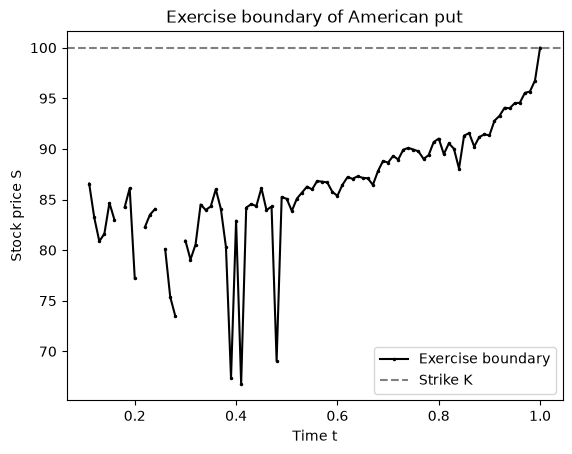

In [ ]:
# Exercise Boundary (put)

import matplotlib.pyplot as plt  

# For exercise boundary - do same loop as for isotonic regression, but saving what the exercise boundary is at each time

def exercise_boundary(paths):
    N = paths.shape[1] - 1 # N = number of time steps (subtracting 1 so not including t=0)
    disc = np.exp(-r * T / N) # discount factor
    P = np.maximum(K - paths[:, -1], 0) # payoff function of put
    boundary = np.full(N + 1, np.nan) # one boundary value per time step; NaN if no exercise region is found
    boundary[N] = K # boundary is K at N because at the end of the time period, we exercise if S<K

    for i in range(N - 1, 0, -1): # same backwards loop
        S = paths[:, i] # prices at time t_i
        P = P * disc # discounted payoff
        itm = K - S > 0 # filters only in-the-money paths (S < K)
        if not itm.any(): # if no in-the-money paths, loop continues
            continue
        X = S[itm] # prices of the selected in-the-money paths
        E = K - X # value of exercising
        exercise = E > centered_isotonic_regression_fit(X, P[itm])  # True if exercising is better than holding

        # want to find barrier that separates exercising (below curve) from holding (above curve):
        # running count of +1 per holder, -1 per exerciser; its minimum marks the best split
        order = np.argsort(X) # indices that sort the prices from low to high
        k = np.argmin(np.r_[0, np.cumsum(np.where(exercise[order], -1, 1))])   # position of the best exercise/hold split
        if k > 0:  # k = 0 means the best split has no exercise region
            boundary[i] = X[order[k - 1]]  # highest price inside the exercise region = boundary estimate

        idx = np.where(itm)[0][exercise]  # indices where it is optimal to exercise
        P[idx] = E[exercise] # replace the payoff for these indices with the exercise value

    return boundary # estimated exercise boundary at each time step

boundary = exercise_boundary(paths_100) # runs the function on the S0 = 100 paths
t = np.linspace(0, T, len(boundary)) # time points

plt.plot(t, boundary, "k.-", ms=3, label="Exercise boundary")  # boundary as black line connecting small dots
plt.axhline(K, ls="--", color="gray", label="Strike K")  # horizontal line at strike K=100
plt.xlabel("Time t")
plt.ylabel("Stock price S")
plt.title("Exercise boundary of American put")
plt.legend()
plt.show()

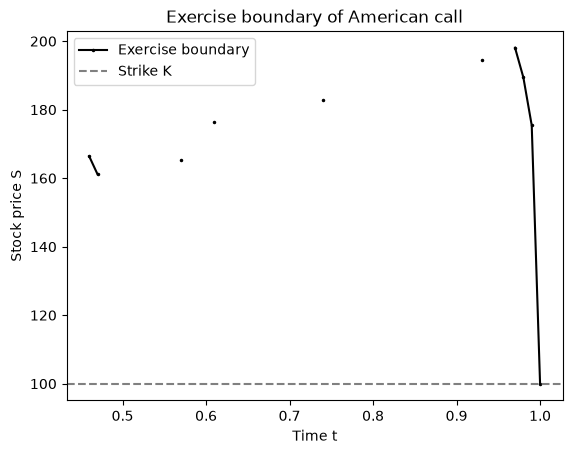

In [ ]:
# Exercise Boundary - American Call
# This will use the centered_isotonic_regression_fit function again, but with increasing = True

# For exercise boundary - do same loop as for isotonic regression, but saving what the exercise boundary is at each time
# Mostly the same loop as put option exercise boundary - just changed payoff function and subsequently the exercise/continuation value
def exercise_boundary_call(paths):
    N = paths.shape[1] - 1 # N = number of time steps (subtracting 1 so not including t=0)
    disc = np.exp(-r * T / N) # discount factor
    P = np.maximum(paths[:, -1] - K, 0) # payoff function of call
    boundary = np.full(N + 1, np.nan) # one boundary value per time step; NaN if no exercise region is found
    boundary[N] = K # boundary is K at N because at expiry, we exercise if S > K

    for i in range(N - 1, 0, -1): # same backwards loop
        S = paths[:, i] # prices at time t_i
        P = P * disc # discounted payoff
        itm = S - K > 0 # filters only in-the-money paths (S > K for a call)
        if not itm.any(): # if no in-the-money paths, loop continues
            continue
        X = S[itm] # prices of the selected in-the-money paths
        E = X - K # value of exercising a call
        exercise = E > centered_isotonic_regression_fit(X, P[itm], increasing=True) # True if exercising is better than holding

        # threshold that best separates exercise (above) from hold (below):
        # prices sorted high to low; running count of +1 per holder, -1 per exerciser; its minimum marks the best split
        order = np.argsort(-X) # indices that sort the prices from high to low
        k = np.argmin(np.r_[0, np.cumsum(np.where(exercise[order], -1, 1))]) # position of the best exercise/hold split
        if k > 0: # k = 0 means the best split has no exercise region
            boundary[i] = X[order[k - 1]] # LOWEST price inside the exercise region = boundary estimate

        idx = np.where(itm)[0][exercise] # indices where it is optimal to exercise
        P[idx] = E[exercise] # replace the payoff for these indices with the exercise value

    return boundary # estimated exercise boundary at each time step

boundary_call = exercise_boundary_call(paths_100) # runs the function on the S0 = 100 paths
t = np.linspace(0, T, len(boundary_call)) # time points

plt.plot(t, boundary_call, "k.-", ms=3, label="Exercise boundary") # boundary as black line with small dots
plt.axhline(K, ls="--", color="gray", label="Strike K") # horizontal line at strike K=100
plt.xlabel("Time t")
plt.ylabel("Stock price S")
plt.title("Exercise boundary of American call")
plt.legend()
plt.show()